# 02 · Lunar surface measurements
Generate topocentric inertial-axis angles and angular rates from the known trajectory.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "configs" / "baseline.json").exists():
    ROOT = ROOT.parent
if not (ROOT / "configs" / "baseline.json").exists():
    raise RuntimeError("Open this notebook from the project root or notebooks directory")
sys.path.insert(0, str(ROOT / "src"))
from halo_tracking.study import load_config
cfg = load_config(ROOT / "configs" / "baseline.json")


In [2]:
from halo_tracking.study import make_truth
from halo_tracking.measurements import simulate, noise_covariance
result = make_truth(cfg)
result["config"] = cfg
result["measurements"] = simulate(result["times"], result["truth"], result["visible"], cfg)
print(cfg["site"])
print(result["diagnostics"])
print("Four-channel covariance:", noise_covariance(cfg, rates=True))

{'latitude_deg': 30.0, 'longitude_east_deg': 270.0, 'radius_km': 1737.4, 'prime_meridian_phase_rad': 3.141592653589793, 'minimum_elevation_deg': 10.0}
{'period_closure_position_km': 99.11216130750401, 'period_closure_velocity_km_s': 9.330359227914614e-05, 'jacobi_range': 4.1675995987588976e-11, 'visible_epochs': 45, 'total_epochs': 389}
Four-channel covariance: [[5.87610763e-10 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 5.87610763e-10 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 2.35044305e-15 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 2.35044305e-15]]


<ipython-input-2-ddef76280971>:3: UserWarning: Supplied rounded state does not close within 1 km. Treat as an initial-value trajectory, not a validated periodic halo.
  result = make_truth(cfg)


## Visibility and measurements
Geometric elevation ≥10° is the only observing gate. Rates are assumed independently measured, not finite differences of these angle samples. Sensor specifications here are illustrative.

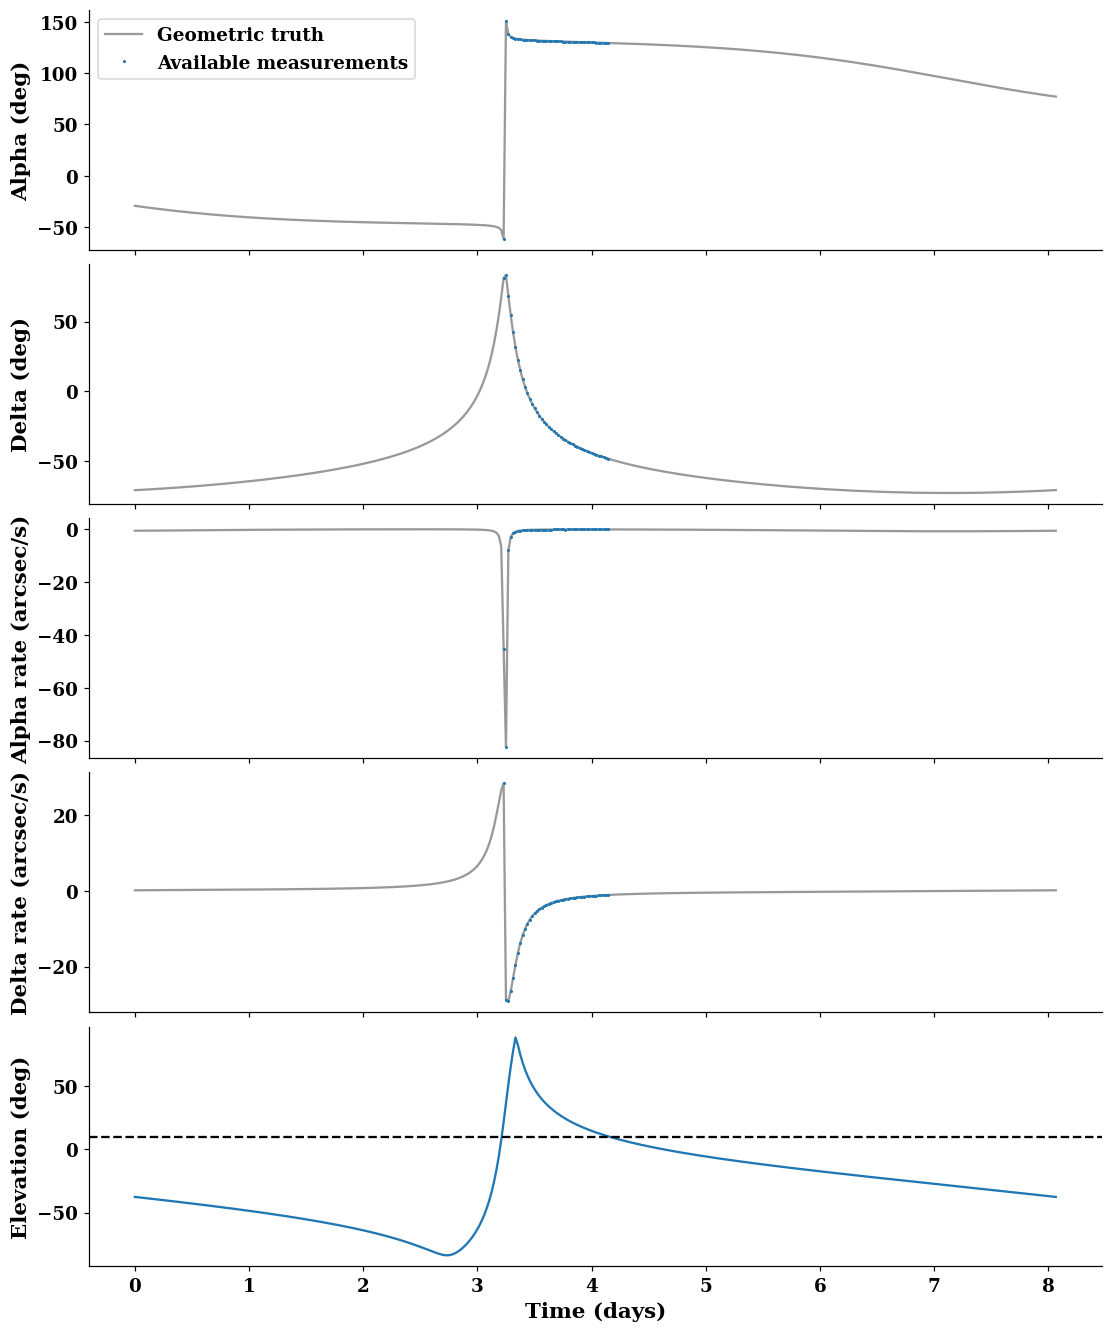

In [3]:
from halo_tracking.plotting import measurement_history, export
fig = measurement_history(result)
export(fig, ROOT / "results/measurements/history.png")